# AO simulation preprocessing

> !!! Batch saving not implemented !!!

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np

import pandas as pd
from matplotlib.patches import Circle
import os
from tqdm import tqdm

import myfunctions

DELETE_RAW_FILES = False

SMALL_SIZE = 20
MEDIUM_SIZE = 22
BIGGER_SIZE = 25
GPU = True
rng_SEED = 42

train_frac = 0.7
val_frac = 0.2

outputDir = "output_prep/"
inputDir = "dataInputs/"
# inputDir= "C:/Users/dominiqu.humbert/Documents/GitHub/AO_simulations/output"

Parameters = "ao_metadata.txt"

metadata = myfunctions.read_metadata_file(inputDir + "metadata.txt")


# display(metadata)

exposureTime = metadata["exposureTime"]
startDelay = metadata["startDelay"]
singleExposureTime = 1/metadata["samplingFreq"] # [ms]
nBatch = metadata["nBatch"]
batchItSize = metadata["batchItSize"]
LastBatchItSize = metadata["LastBatchItSize"]
n = exposureTime + startDelay

interactionMarixSize = metadata["interactionMarixSize"]

# print("batchItSize: ", batchItSize)

# RWFE

1. Initialized but unused iterations are dropped.

In [ ]:
RWFE = np.empty(nBatch * batchItSize) # The array is trimmed later
# tqdm(range(n_iter), desc="circle_to_square"):
start = 0
for batch in tqdm(range(1, nBatch + 1), desc="Reading RWFE batches"):
    # print(f"Reading batch {batch} of {nBatch}")
    fname = os.path.join(inputDir, f"ao_rwfe_{batch}.h5")
    with h5py.File(fname, "r") as temp:
        key = list(temp.keys())[0]
        data = temp[key][()][:]
        end = start + data.shape[1]
        RWFE[start:end] = data
        start = end

RWFE = RWFE[ : (nBatch-1) * batchItSize + LastBatchItSize]
ticks_spacing = 10 # [s]
# print(exposureTime)
# print(singleExposureTime)
ticks = np.arange(0, exposureTime + 1, ticks_spacing/singleExposureTime)


RWFE_mean = np.mean(RWFE[startDelay:])
xlims = [0, (nBatch-1) * batchItSize + LastBatchItSize]

# print("RWFE mean: ", RWFE_mean)

plt.close(0)
plt.figure(0,figsize=(10,6))
plt.semilogy(RWFE, 'k', label="RWFE")
plt.hlines(RWFE_mean, startDelay, xlims[1], colors='r', linestyles='dashed', label="Mean RWFE")
plt.vlines(startDelay, 0.01,1, colors='b', label="Start Delay")
plt.ylabel("RWFE [$\\lambda$]", fontsize=MEDIUM_SIZE)
plt.xlabel("t [s]", fontsize=MEDIUM_SIZE)
plt.suptitle("RWFE vs Time", fontsize=BIGGER_SIZE)
plt.title(f"Exposure: {exposureTime*singleExposureTime} s, Start Delay: {startDelay*singleExposureTime} s, Samp.Freq: {1/singleExposureTime} Hz", fontsize=SMALL_SIZE)
plt.xlim([*xlims])
plt.xticks(ticks, [f"{singleExposureTime*t}" for t in ticks], fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.grid()
plt.legend(fontsize=MEDIUM_SIZE)
plt.tight_layout()
plt.show()
# plt.savefig(outputDir+"/rwfe.png", dpi=300)
# 
del RWFE

# Data split

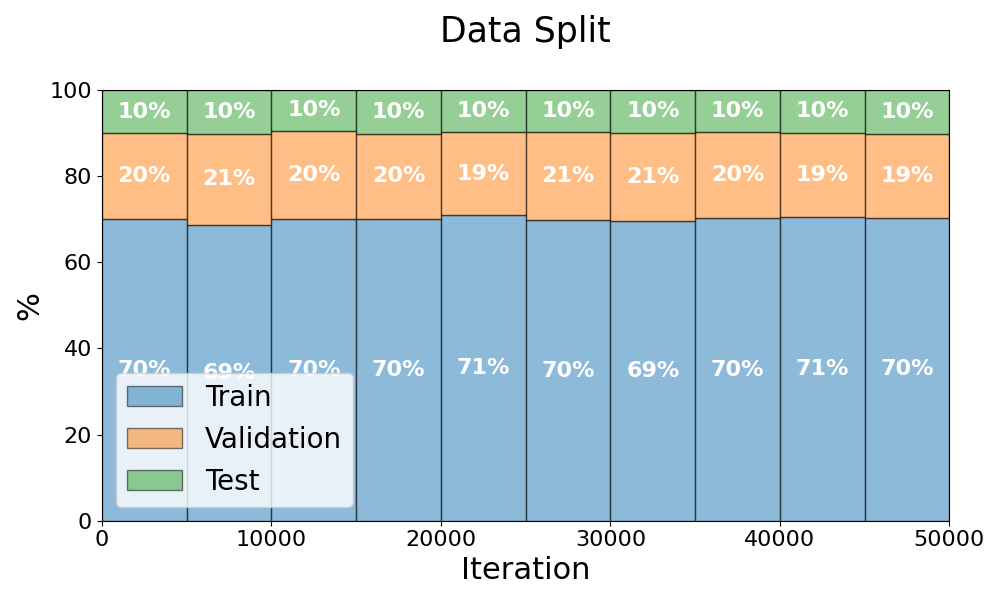

In [2]:
rng = np.random.default_rng(rng_SEED)
n = 50000
indices = rng.permutation(n)  # shuffle indices

n_train = int(train_frac * n)
n_val = int(val_frac * n)

train_id = indices[:n_train]
val_id = indices[n_train:n_train + n_val]
test_id = indices[n_train + n_val:]

# plt.close(0)
# plt.figure(0, figsize=(10, 6))
# plt.hist(train_id, bins=10, alpha=0.5, label="Train", color='#1f77b4',  edgecolor="black", linewidth=1.0)
# plt.hist(val_id, bins=10, alpha=0.5, label="Validation", color='#ff7f0e', edgecolor="black", linewidth=1.0)
# plt.hist(test_id, bins=10, alpha=0.5, label="Test", color='#2ca02c', edgecolor="black", linewidth=1.0)
# plt.xlabel("Iteration", fontsize=MEDIUM_SIZE)
# plt.ylabel("Count", fontsize=MEDIUM_SIZE)
# plt.legend()
# plt.title("Data Split", fontsize=BIGGER_SIZE)
# plt.tight_layout()
# plt.show()
# plt.savefig(outputDir+"/data_split.png", dpi=300)

bins = np.linspace(0, exposureTime, 11)
c1, _ = np.histogram(train_id, bins)
c2, _ = np.histogram(val_id, bins)
c3, _ = np.histogram(test_id, bins)

tot = c1 + c2 + c3
p1, p2, p3 = 100*c1/tot, 100*c2/tot, 100*c3/tot
x = (bins[:-1] + bins[1:]) / 2
w = np.diff(bins)

fig, ax = plt.subplots(figsize=(10, 6))
b1 = ax.bar(x, p1, w, label='Train', alpha=0.5, color='#1f77b4', edgecolor='black')
b2 = ax.bar(x, p2, w, bottom=p1, label='Validation', alpha=0.5, color='#ff7f0e', edgecolor='black')
b3 = ax.bar(x, p3, w, bottom=p1+p2, label='Test', alpha=0.5, color='#2ca02c', edgecolor='black')

for b in (b1, b2, b3):
    ax.bar_label(b, fmt='%.0f%%', label_type='center', color='white',weight='bold',fontsize=SMALL_SIZE*.8)

ax.set_xlabel('Iteration', fontsize=MEDIUM_SIZE)
ax.set_ylabel('%', fontsize=MEDIUM_SIZE)
ax.set_ylim(0, 100)
ax.set_xlim(0, exposureTime)
ax.tick_params(axis='both', labelsize=SMALL_SIZE*.8)
ax.set_title('Data Split\n', fontsize=BIGGER_SIZE)
ax.legend(fontsize = SMALL_SIZE)
plt.tight_layout()
plt.savefig(outputDir + "/data_split.png", dpi=300)
plt.show()

In [ ]:
rng = np.random.default_rng(rng_SEED)
n = 50000
indices = rng.permutation(n)  # shuffle indices

n_train = int(train_frac * n)
n_val = int(val_frac * n)

train_id = indices[:n_train]
val_id = indices[n_train:n_train + n_val]
test_id = indices[n_train + n_val:]

# plt.close(0)
# plt.figure(0, figsize=(10, 6))
# plt.hist(train_id, bins=10, alpha=0.5, label="Train", color='#1f77b4',  edgecolor="black", linewidth=1.0)
# plt.hist(val_id, bins=10, alpha=0.5, label="Validation", color='#ff7f0e', edgecolor="black", linewidth=1.0)
# plt.hist(test_id, bins=10, alpha=0.5, label="Test", color='#2ca02c', edgecolor="black", linewidth=1.0)
# plt.xlabel("Iteration", fontsize=MEDIUM_SIZE)
# plt.ylabel("Count", fontsize=MEDIUM_SIZE)
# plt.legend()
# plt.title("Data Split", fontsize=BIGGER_SIZE)
# plt.tight_layout()
# plt.show()
# plt.savefig(outputDir+"/data_split.png", dpi=300)

bins = np.linspace(0, exposureTime, 11)
c1, _ = np.histogram(train_id, bins)
c2, _ = np.histogram(val_id, bins)
c3, _ = np.histogram(test_id, bins)

tot = c1 + c2 + c3
p1, p2, p3 = 100*c1/tot, 100*c2/tot, 100*c3/tot
x = (bins[:-1] + bins[1:]) / 2
w = np.diff(bins)

fig, ax = plt.subplots(figsize=(10, 6))
b1 = ax.bar(x, p1, w, label='Train', alpha=0.5, color='#1f77b4', edgecolor='black')
b2 = ax.bar(x, p2, w, bottom=p1, label='Validation', alpha=0.5, color='#ff7f0e', edgecolor='black')
b3 = ax.bar(x, p3, w, bottom=p1+p2, label='Test', alpha=0.5, color='#2ca02c', edgecolor='black')

for b in (b1, b2, b3):
    ax.bar_label(b, fmt='%.0f%%', label_type='center', color='white',weight='bold',fontsize=SMALL_SIZE*.8)

ax.set_xlabel('Iteration', fontsize=MEDIUM_SIZE)
ax.set_ylabel('%', fontsize=MEDIUM_SIZE)
ax.set_ylim(0, 100)
ax.set_xlim(0, exposureTime)
ax.tick_params(axis='both', labelsize=SMALL_SIZE*.8)
ax.set_title('Data Split\n', fontsize=BIGGER_SIZE)
ax.legend(fontsize = SMALL_SIZE)
plt.tight_layout()
plt.savefig(outputDir + "/data_split.png", dpi=300)
plt.show()

## DM preprocessing

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.
3. The data is reshaped from 1x97 to 11x11 arrays with zero values where the (11*11-97) don't exist

In [ ]:
act_tot = metadata["nActWSF"] + 2*metadata["edge_act"]
nact = 97

ao_DM = np.empty((nBatch * batchItSize, nact)) # The array is trimmed later

start = 0
for batch in tqdm(range(1, nBatch + 1), desc="Reading AO DM batches"):
    # print(f"Reading batch {batch} of {nBatch}")
    fname = os.path.join(inputDir, f"ao_DM_{batch}.h5")
    with h5py.File(fname, "r") as temp:
        key = list(temp.keys())[0]
        data = temp[key][()][:]
        end = start + data.shape[0]
        ao_DM[start:end] = data
        start = end

ao_DM = ao_DM[startDelay : (nBatch-1) * batchItSize + LastBatchItSize]

n_iter = int(- startDelay + (nBatch - 1) * batchItSize + LastBatchItSize)

DM = np.zeros((n_iter, int(act_tot), int(act_tot)))


print(n_iter)
for i in tqdm(range(n_iter), desc="circle_to_square"):
    DM[i] = myfunctions.circle_to_square(ao_DM[i], Nact1D=int(act_tot))


if os.path.exists(inputDir+"/ao_DM_"+str(1)+".h5"):
    if DELETE_RAW_FILES: os.remove(inputDir+"/ao_DM_"+str(1)+".h5")
with h5py.File(outputDir+"/ao_DM_train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training DM commands", data=DM[train_id])
with h5py.File(outputDir+"/ao_DM_val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation DM commands", data=DM[val_id])
with h5py.File(outputDir+"/ao_DM_test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test DM commands", data=DM[test_id])

plt.close(0)
plt.figure(0)
plt.imshow(DM[0])
circle = Circle((5, 5), 4.5, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.title("DM command map at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()
plt.ylabel("Actuator Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Actuator X", fontsize=MEDIUM_SIZE)
plt.tight_layout()

del ao_DM
del DM

## WFS

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.
3. $\frac{\partial W}{dx}$ and $\frac{\partial W}{dx}$ are separated

In [ ]:
n_iter = int(- startDelay + (nBatch - 1) * batchItSize + LastBatchItSize)
act_tot = int(metadata["nActWSF"] + 2*metadata["edge_act"])
nSlopes = interactionMarixSize

n_slopes_1D = act_tot-1

WFSxy = np.empty((full_len, interactionMarixSize), dtype=np.float32)


start = 0
for batch in tqdm(range(1, nBatch + 1), desc="Reading AO WFS batches"):
    fname = os.path.join(inputDir, f"ao_WFS_{batch}.h5")
    with h5py.File(fname, "r") as temp:
        key = list(temp.keys())[0]
        data = temp[key][()]  # full dataset
        end = start + data.shape[0]
        WFSxy[start:end] = data
        start = end

WFSxy = WFSxy[startDelay : (nBatch - 1) * batchItSize + LastBatchItSize, :]

WFSx = np.zeros((n_iter, n_slopes_1D, n_slopes_1D), dtype=WFSxy.dtype)
WFSy = np.zeros((n_iter, n_slopes_1D, n_slopes_1D), dtype=WFSxy.dtype)


for i in tqdm(range(n_iter), desc="WFS circle_to_square"):
    WFSx[i] = myfunctions.circle_to_square(WFSxy[i, 0:WFSxy.shape[1]//2],n_slopes_1D)
    WFSy[i] = myfunctions.circle_to_square(WFSxy[i, WFSxy.shape[1]//2:],n_slopes_1D)

if DELETE_RAW_FILES:
    for batch in tqdm(range(1, nBatch + 1), desc="Clearing raw WFS files"):
        fname = os.path.join(inputDir, f"ao_WFS_{batch}.h5")
        if os.path.exists(fname):
            os.remove(fname)

with h5py.File(outputDir+"/ao_WFSx_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training WFS x", data=WFSx[train_id])
with h5py.File(outputDir+"/ao_WFSy_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training WFS y", data=WFSy[train_id])
with h5py.File(outputDir+"/ao_WFSx_"+"val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation WFS x", data=WFSx[val_id])
with h5py.File(outputDir+"/ao_WFSy_"+"val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation WFS y", data=WFSy[val_id])
with h5py.File(outputDir+"/ao_WFSx_"+"test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test WFS x", data=WFSx[test_id])
with h5py.File(outputDir+"/ao_WFSy_"+"test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test WFS y", data=WFSy[test_id])


plt.close(0)
plt.figure(0)
plt.imshow(WFSx[0])
plt.ylabel("Subaperture Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Subaperture X", fontsize=MEDIUM_SIZE)
plt.title("WFS x-slope map at iteration 0", fontsize=BIGGER_SIZE)
circle = Circle((4.5, 4.5), 5, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.colorbar()
plt.tight_layout()
plt.show()

del WFSxy
del WFSx
del WFSy

## Lightfield

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.

In [ ]:
first_fname = os.path.join(inputDir, f"ao_lightfield_{1}.h5")
with h5py.File(first_fname, "r") as temp:
    key = list(temp.keys())[0]
    sample_data = temp[key][()]
    lightfield_dim = sample_data.shape

full_len = nBatch * batchItSize
lightfields = np.empty((full_len, lightfield_dim[1], lightfield_dim[2]), dtype=np.float32)

start = 0
for batch in tqdm(range(1, nBatch + 1), desc="Reading AO lightfield batches"):
    fname = os.path.join(inputDir, f"ao_lightfield_{batch}.h5")
    with h5py.File(fname, "r") as temp:
        key = list(temp.keys())[0]
        data = temp[key][()]  # full dataset
        end = start + data.shape[0]
        lightfields[start:end] = data
        start = end

lightfields = lightfields[startDelay : (nBatch - 1) * batchItSize + LastBatchItSize, :, :]



if DELETE_RAW_FILES:
    for batch in tqdm(range(1, nBatch + 1), desc="Clearing raw lightfield files"):
        fname = os.path.join(inputDir, f"ao_lightfield_{batch}.h5")
        if os.path.exists(fname):
            os.remove(fname)

with h5py.File(outputDir+"/ao_lightfield_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Lightfield", data=lightfields[train_id])
with h5py.File(outputDir+"/ao_lightfield_"+"val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Lightfield", data=lightfields[val_id])
with h5py.File(outputDir+"/ao_lightfield_"+"test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Lightfield", data=lightfields[test_id])

plt.close(0)
plt.figure(0)
plt.imshow(lightfields[0])
plt.title("Lightfield image at iteration 0", fontsize=BIGGER_SIZE)
circle = Circle((270/2, 270/2), 270/2, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.colorbar()
plt.ylabel("Pixel Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Pixel X", fontsize=MEDIUM_SIZE)
plt.tight_layout()


del lightfields

# Intensity map

In [ ]:
nPx_SHWFS = metadata["nPx"]
nL = metadata["nActWSF"]

first_fname = os.path.join(inputDir, f"ao_lightfield_{1}.h5")
with h5py.File(first_fname, "r") as temp:
    key = list(temp.keys())[0]
    sample_data = temp[key][()]
    _, width, height = sample_data.shape

full_len = nBatch * batchItSize
lightfields = np.empty((full_len, width, height), dtype=sample_data.dtype)

start = 0
for batch in tqdm(range(1, nBatch + 1), desc="Reading AO lightfield batches"):
    fname = os.path.join(inputDir, f"ao_lightfield_{batch}.h5")
    with h5py.File(fname, "r") as temp:
        key = list(temp.keys())[0]
        data = temp[key][()]  # full dataset
        end = start + data.shape[0]
        lightfields[start:end] = data
        start = end
        
lightfields = lightfields[startDelay : (nBatch - 1) * batchItSize + LastBatchItSize, :, :]
print(lightfields.shape)

n, width, height = lightfields.shape

lenset_height = width//nL
lenset_width = height//nL

intensityMap = np.zeros((n, nL, nL))
print("intensityMap shape:", intensityMap.shape)

# for i in tqdm(range(n)):
#     for j in range(nL):
#         for k in range(nL):
#             print(f"Processing iteration {i}, px ({j*lenset_height}->{(j+1)*lenset_height}, {k*lenset_width}->{(k+1)*lenset_width})")
#             intensityMap[i, j, k] = lightfields[i, j*lenset_height:(j+1)*lenset_height, k*lenset_width:(k+1)*lenset_width].sum()

intensityMap = lightfields.reshape(n, nL, lenset_height, nL, lenset_width).sum(axis=(2, 4)) # https://stackoverflow.com/questions/25173979/aggregate-numpy-array-by-summing

if DELETE_RAW_FILES:
    for batch in tqdm(range(1, nBatch + 1), desc="Clearing raw lightfield files"):
        fname = os.path.join(inputDir, f"ao_lightfield_{batch}.h5")
        if os.path.exists(fname):
            os.remove(fname)

with h5py.File(outputDir+"/ao_intensity_map_train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training intensity map", data=intensityMap[train_id])
with h5py.File(outputDir+"/ao_intensity_map_val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation intensity map", data=intensityMap[val_id])
with h5py.File(outputDir+"/ao_intensity_map_test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test intensity map", data=intensityMap[test_id])

plt.close(0)
plt.figure(0)
plt.imshow(intensityMap[0])
plt.title("Intensity map at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()


# iPSF

# PSF

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.

Reading AO iPSF batches: 100%|██████████| 8/8 [00:01<00:00,  4.05it/s]


(50000, 80, 80)


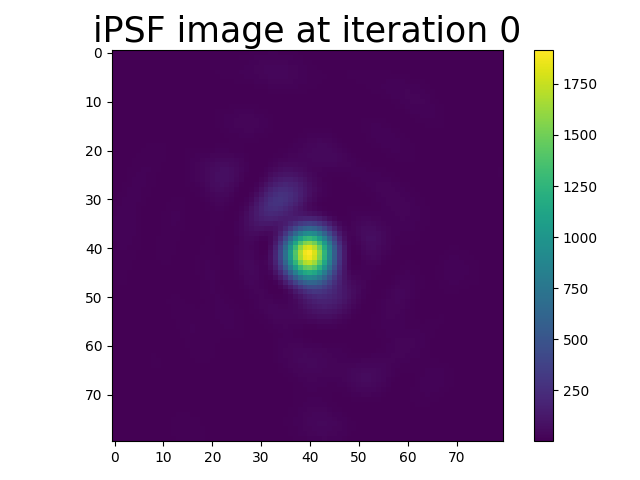

In [4]:
first_fname = os.path.join(inputDir, f"ao_ipsf_{1}.h5")
with h5py.File(first_fname, "r") as temp:
    key = list(temp.keys())[0]
    sample_data = temp[key][()]
    ipsf_feature_shape = sample_data.shape[1:]

full_len = nBatch * batchItSize
iPSFs = np.empty((full_len, *ipsf_feature_shape), dtype=sample_data.dtype)

start = 0
for batch in tqdm(range(1, nBatch + 1), desc="Reading AO iPSF batches"):
    fname = os.path.join(inputDir, f"ao_ipsf_{batch}.h5")
    with h5py.File(fname, "r") as temp:
        key = list(temp.keys())[0]
        data = temp[key][()]  # full dataset
        end = start + data.shape[0]
        iPSFs[start:end] = data
        start = end
iPSFs = iPSFs[startDelay : (nBatch - 1) * batchItSize + LastBatchItSize]

if DELETE_RAW_FILES:
    for batch in tqdm(range(1, nBatch + 1), desc="Clearing raw iPSF files"):
        fname = os.path.join(inputDir, f"ao_ipsf_{batch}.h5")
        if os.path.exists(fname):
            os.remove(fname)

with h5py.File(outputDir+"/ao_ipsf_"+"train_"+str(1)+".h5", "w") as f:
    f.create_dataset("Training iPSF", data=iPSFs[train_id])
with h5py.File(outputDir+"/ao_ipsf_"+"val_"+str(1)+".h5", "w") as f:
    f.create_dataset("Validation iPSF", data=iPSFs[val_id])
with h5py.File(outputDir+"/ao_ipsf_"+"test_"+str(1)+".h5", "w") as f:
    f.create_dataset("Test iPSF", data=iPSFs[test_id])

print(iPSFs.shape)
plt.close(0)
plt.figure(0)
plt.imshow(iPSFs[test_id[0]])
plt.title("iPSF image at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()
plt.tight_layout()

del iPSFs

# Splitting data

In [ ]:
# create a .h5 file containing train_id, val_id and test_id. the file should be easy to read and parse later on.
with h5py.File(outputDir+"/data_split.h5", "w") as f:
    f.create_dataset("train_id", data=train_id)
    f.create_dataset("val_id", data=val_id)
    f.create_dataset("test_id", data=test_id)

